<a href="https://pulse.simudyne.com"><img src="_notebook_assets/Simudyne_Symbol_Logotype_BLUE_RGB.png" width="320" alt="Simudyne"></a>

# Pulse FM QuickStart

> **Simudyne Pulse · Production** — runs against `https://pulse-api.simudyne.com` with the `simudyne-pulse` SDK.

The shortest path from an API key to a generated order book. No data needed — with no market named, the model runs on its own test day.

📖 **Docs:** [Quickstart](https://pulse.simudyne.com/docs/quickstart) · [Foundation models](https://pulse.simudyne.com/docs/foundation-models) · [Output format](https://pulse.simudyne.com/docs/output-format) · [API reference](https://pulse.simudyne.com/docs/api-reference)

### Setup

`pip install simudyne-pulse` and set your key — `export SIMUDYNE_API_KEY=pk_live_...`, or pass
`PulseABM(api_key=...)`. Keys come from your [account page](https://pulse.simudyne.com/docs/api-keys); see
[Authentication](https://pulse.simudyne.com/docs/authentication).

A production run is a **job**: `run()` returns at once with a `job_id`, the model runs on
Pulse's compute, and `wait()` below polls it every 20 seconds until it finishes.

In [1]:
import time

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import clear_output
from simudyne import PulseABM

client = PulseABM()   # reads SIMUDYNE_API_KEY; points at production by default


def wait(job_id, every=20):
    """Poll a job until every run has finished and its results can be read."""
    start = time.time()
    while True:
        status = client.simulation.get_job_status(job_id)
        clear_output(wait=True)
        note = "" if status["is_complete"] else status.get("message") or ""
        print(f"{job_id}  {time.time() - start:4.0f}s  {status['status_summary']}  {note}")
        if status["is_complete"]:
            sims = client.simulation.get_job_results(job_id)["simulations"]
            if all(s.get("metrics") or s["status"] in ("error", "failed") for s in sims):
                break
        time.sleep(every)
    if status["has_errors"]:
        print(client.simulation.get_job_logs(job_id)[-2000:])
    return status


def generated(sim_id):
    """The model's own rows: sim_data.parquet minus the real warm-start context."""
    book = client.simulation.get_sim_data(sim_id)
    segments = client.simulation.get_sim_metrics(sim_id)["segments"]
    return pl.concat([book.slice(a, b - a) for a, b in (s["generated"] for s in segments)])


def mid(frame):
    return frame.select("timestamp", mid=(pl.col("bid_price_1") + pl.col("ask_price_1")) / 2)


def style(ax, title, ylabel="mid"):
    ax.set(title=title, ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.margins(x=0)

## 1. What can production run?

`client.fm.models()` lists the foundation models live in production: the name to run, the
markets each accepts a prompt from, its test day, and the knobs it takes.
See [Models and their names](https://pulse.simudyne.com/docs/foundation-models).

In [2]:
models = client.fm.models()["models"]

for m in models:
    print(m["production_name"], "|", m["model_id"], "|", m["supported_data"], "| test day:", m.get("testdata"))

# What you see above depends on your account. Pick one by name:
MODEL = "flow-lse-1-54M"   # the public LSE model, with a built-in test day

flow-hkex-1-100M | flob-adaln-rf-1s | [{'provider': 'bmll', 'exchange': 'hkex_securities'}] | test day: {}
flow-lse-1-100M | flob-adaln-rf-1s-lse | [{'provider': 'bmll', 'exchange': 'lse'}] | test day: {}
flow-lse-1-54M | flob-adaln-rf-1s-lse-54m | [{'provider': 'bmll', 'exchange': 'lse'}] | test day: {'provider': 'bmll', 'exchange': 'lse', 'symbol': 'SHEL', 'date': '2026-06-01'}


## 2. Generate three seeded paths

Five minutes from the open, three draws. Naming no `symbol`/`cal_date`/`provider`/`exchange`
runs the model's test day. `run()` returns straight away; `wait()` is the polling.

In [3]:
job = client.simulation.run(engine="fm", model_id=MODEL, duration_minutes=5, n_runs=3, seed=7)
job

{'job_id': 'c5036adc-6456-414e-980d-83a079559e66',
 'model_id': 'flob-adaln-rf-1s-lse-54m',
 'version': '1.0.2',
 'sim_ids': ['bmll:lse:SHEL:2026-06-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:na:na:faf34893:normal_99914b93:baseline:0000',
  'bmll:lse:SHEL:2026-06-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:na:na:faf34893:normal_99914b93:baseline:0001',
  'bmll:lse:SHEL:2026-06-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:na:na:faf34893:normal_99914b93:baseline:0002'],
 'compute_profile': 'cpu',
 'n_runs': 3,
 'engine': 'fm'}

In [4]:
status = wait(job["job_id"])

c5036adc-6456-414e-980d-83a079559e66   133s  {'complete': 3}  


`get_job_results()` is the first thing to look at after any run — one entry per sim with its
status and metrics. `n_generated` is the rows the model made; the rest of `n_rows` is the real
warm-start context it was prompted with.

In [5]:
results = client.simulation.get_job_results(job["job_id"])

pl.DataFrame([
    {"sim": i, "status": s["status"], "n_rows": s["metrics"].get("n_rows"),
     "n_generated": s["metrics"].get("n_generated"), "compute_time_s": s["metrics"].get("compute_time_s")}
    for i, s in enumerate(results["simulations"])
])

sim,status,n_rows,n_generated,compute_time_s
i64,str,i64,i64,f64
0,"""complete""",333,300,107.11
1,"""complete""",333,300,107.11
2,"""complete""",333,300,107.11


## 3. The mid price

Each draw is plotted on its own so every line stays continuous. `generated()` (in the setup
cell) drops the warm-start rows using the `segments` the run reports — drawing those as if the
model made them puts real data inside the generated paths.
See [Prompt context in the output](https://pulse.simudyne.com/docs/foundation-models).

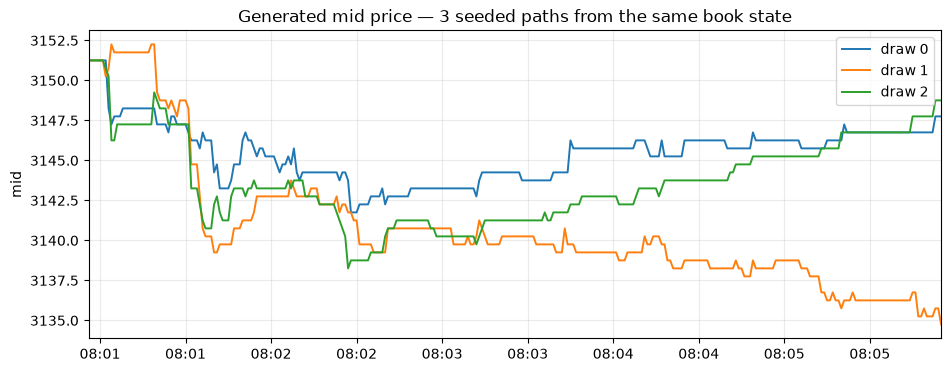

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))

for i, sim_id in enumerate(job["sim_ids"]):
    m = mid(generated(sim_id))
    ax.plot(m["timestamp"], m["mid"], lw=1.4, label=f"draw {i}")

style(ax, "Generated mid price — 3 seeded paths from the same book state")
ax.legend();

## 4. It generated a book, not a price

`sim_data.parquet` is every message with full depth at each one. Reading the last row out as
ladders shows the book at the end of the run. Column reference: [Output format](https://pulse.simudyne.com/docs/output-format).

In [7]:
book = client.simulation.get_sim_data(job["sim_ids"][0])
print(f"{len(book):,} messages, {len(book.columns)} columns")

last = book.row(-1, named=True)


def ladder(side):
    out = []
    for i in range(1, 11):
        price, size = last.get(f"{side}_price_{i}"), last.get(f"{side}_size_{i}")
        if not price or not size or price <= 0:
            break
        out.append((price, size))
    return out


bids, asks = ladder("bid"), ladder("ask")
biggest = max((s for _, s in bids + asks), default=1)
bar = lambda size: "█" * max(1, round(30 * size / biggest))

print(f"\nas of {last['timestamp']}\n")
for price, size in reversed(asks):
    print(f"{price:>10.4f}  {bar(size):<30} {size:,.0f}")
print(f"{'':>10}  {'─' * 12} ask ─┼─ bid")
for price, size in bids:
    print(f"{price:>10.4f}  {bar(size):<30} {size:,.0f}")

333 messages, 62 columns

as of 2026-06-01 08:05:55

 3153.2500  ███████████████                983
 3152.7500  ███████████████                986
 3152.2500  █████████████████              1,091
 3151.7500  ██████████████████████         1,413
 3151.2500  █████████████████              1,088
 3150.7500  █████████████████████          1,375
 3150.2500  ██████████████                 915
 3149.7500  ██████████                     649
 3149.2500  ████████████                   782
 3148.7500  ████                           270
            ──────────── ask ─┼─ bid
 3146.7500  █████████                      569
 3146.2500  ██████████                     660
 3145.7500  ███████████████                998
 3145.2500  ████████████████               1,081
 3144.7500  ███████████████                964
 3144.2500  █████████████████              1,089
 3143.7500  ██████████████████             1,149
 3143.2500  █████████████████              1,099
 3142.7500  ██████████████████████████████ 1,966

The same book sampled once a second is **`l2_by_second.parquet`** — ten levels a side, the
shape for plotting depth or spread over time. Every file a run can write is listed in
[Download data](https://pulse.simudyne.com/docs/available-data).

['l2_by_second.parquet', 'mid_price_by_min.parquet', 'params.json', 'results.json', 'sim_data.parquet']


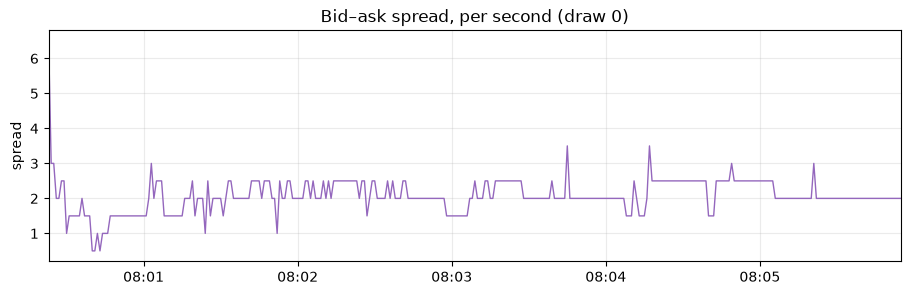

In [8]:
print(client.simulation.list_sim_files(job["sim_ids"][0])["files"])

snaps = client.simulation.get_sim_data(job["sim_ids"][0], "l2_by_second.parquet")
spread = snaps.select("time", spread=pl.col("ask_price_1") - pl.col("bid_price_1"))

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(spread["time"], spread["spread"], lw=1.0, color="tab:purple")
style(ax, "Bid–ask spread, per second (draw 0)", "spread")

## 5. What was run, what came out, what it said

| call | what it is |
|---|---|
| `get_sim_params(sim_id)` | the resolved parameters — every knob, including the defaults you did not set |
| `get_sim_metrics(sim_id)` | counts, compute time, the generated window and the warm-start split |
| `get_job_logs(job_id)` | the model's own output — read this first when a run fails |

In [9]:
client.simulation.get_sim_params(job["sim_ids"][0])["sim_params"]

{'sim_param_hash': 'faf34893',
 'mc_number': 0,
 'seed': 7,
 'horizon_minutes': 5.0,
 'horizon_frames': None,
 'device': 'cpu',
 'model_id': 'flob-adaln-rf-1s-lse-54m',
 'model_version': '1.0.2',
 'gen_method': 'FM-flob-adaln-rf-1s-lse-54m_v1.0.2',
 'model_args': {'num_steps': 10,
  'method': 'euler',
  'guidance': 1.0,
  'historical_conditions': True,
  'null_future_conditions': False,
  'refresh_cycle': 20,
  'impact_model': 'resilience',
  'impact_seconds': 10.0,
  'impact_coefficient': 1.0},
 'generated_window': {'start': '2026-06-01T08:00:56',
  'end': '2026-06-01T08:05:55'},
 'sessions': ['']}

In [10]:
client.simulation.get_sim_metrics(job["sim_ids"][0])

{'total_orders': 0,
 'total_trades': 0,
 'cancel_rate': 0.0,
 'compute_time_s': 107.11,
 'mem_usage_mb': 0.0,
 'agent_breakdown': {},
 'n_generated': 300,
 'n_rows': 333,
 'generated_window': {'start': '2026-06-01T08:00:56',
  'end': '2026-06-01T08:05:55'},
 'segments': [{'period': '', 'historical': [0, 33], 'generated': [33, 333]}]}

In [11]:
print(client.simulation.get_job_logs(job["job_id"])[-1500:])   # the tail

tmp/tmp98y1gib7/SHEL_2026-06-01_Session1_2.parquet \xe2\x86\x92 /tmp/fm_out/data/SHEL_2026-06-01_Session1_2.parquet\n2026-11-27 14:50:24 | flob.deploy.model                    | INFO     | saved SHEL_2026-06-01_Session1_2 (333 rows: 33 historical + 300 generated)\n2026-11-27 14:50:27 | fm_harness.sinks                     | INFO     | results delivered to orchestrator: {\'received\': 3, \'job_id\': \'c5036adc-6456-414e-980d-83a079559e66\'}\n{\n  "model_id": "flob-adaln-rf-1s-lse-54m",\n  "version": "1.0.2",\n  "gen_method": "FM-flob-adaln-rf-1s-lse-54m_v1.0.2",\n  "job_id": "c5036adc-6456-414e-980d-83a079559e66",\n  "seed": 7,\n  "n_runs": 3,\n  "exec_algo": false,\n  "horizon": null,\n  "device": "cpu",\n  "batches": 1,\n  "sims": {\n    "bmll:lse:SHEL:2026-06-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:s7:Session1:r0:c5036adc": [\n      "/tmp/fm_out/data/SHEL_2026-06-01_Session1_0.parquet"\n    ],\n    "bmll:lse:SHEL:2026-06-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:s7:Session1:r1:c5036adc": [

## 6. What you can run, and on what

Every Pro account can run the **public models on CPU**. Restricted models and GPUs are enabled
per account, and your profile says which you have: `fm_access["models"]` are the restricted
models granted to you, `fm_access["gpus"]` the GPUs you can name as `device`.

In [12]:
access = client.profile.get()["fm_access"]

print("Models you can run:   ", [m["production_name"] or m["model_id"] for m in client.fm.models()["models"]])
print("Restricted models on: ", access["models"] or "none — public models only")
print("GPUs on this account: ", access["gpus"] or "none — CPU only")

Models you can run:    ['flow-hkex-1-100M', 'flow-lse-1-100M', 'flow-lse-1-54M']
Restricted models on:  ['flob-adaln-rf-1s', 'flob-adaln-rf-1s-lse']
GPUs on this account:  ['a100', 'l4', 't4']


### Need more?

To use a restricted model, a GPU, or a bigger GPU, **[contact us](https://pulse.simudyne.com/feedback)**
or email [support@simudyne.com](mailto:support@simudyne.com?subject=Pulse%20FM%20access) with the
email your account is registered under and the models or GPUs you want. Access is added to your
existing key — nothing to change in your code. See [Compute and pricing](https://pulse.simudyne.com/docs/foundation-models).

## 7. The same run on a GPU

`device` picks the hardware a run is placed on. Production offers:

| `device` | hardware | approx. $/hour |
|---|---|---|
| `cpu` | CPU — every account | 0.10 |
| `t4` | NVIDIA T4, 16 GB — the smallest GPU, and what `"gpu"` means | 0.75 |
| `l4` | NVIDIA L4, 24 GB | 0.85 |
| `a100` | NVIDIA A100, 40 GB | 3.70 |

A GPU you have not been granted is refused with a `403`. The device is part of the run's
parameters, so a T4 run of the same day is a different sim from the CPU one.

Same model, same day, same seed — on the smallest GPU:

In [13]:
gpu_job = client.simulation.run(engine="fm", model_id=MODEL, duration_minutes=5, n_runs=3, seed=7, device="t4")
status = wait(gpu_job["job_id"])

a5563dd1-7e98-4457-8d31-515dcf4e798d    63s  {'complete': 3}  


CPU: ran on cpu  params hash faf34893
T4: ran on gpu  params hash a767e544


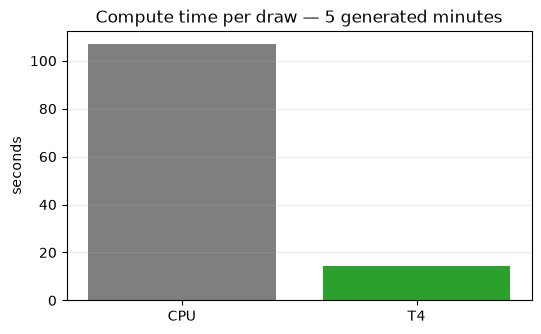

In [14]:
for name, j in (("CPU", job), ("T4", gpu_job)):
    sim_params = client.simulation.get_sim_params(j["sim_ids"][0])["sim_params"]
    print(f"{name}: ran on {sim_params['device']:<4} params hash {j['sim_ids'][0].split(':')[7]}")

secs = {name: [client.simulation.get_sim_metrics(s)["compute_time_s"] for s in j["sim_ids"]]
        for name, j in (("CPU", job), ("T4", gpu_job))}

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(list(secs), [sum(v) / len(v) for v in secs.values()], color=["tab:gray", "tab:green"])
ax.set(title="Compute time per draw — 5 generated minutes", ylabel="seconds")
ax.grid(alpha=0.25, axis="y")

---

That is the whole loop: **run → wait → read**. Next:

- **`01-your-own-day.ipynb`** — run the model on any day in the catalogue
- **`02-exec-algos.ipynb`** — place an execution algorithm in the market and measure the cost
- **`03-previous-results.ipynb`** — get a run back when you no longer have the `job`

Full guide: [pulse.simudyne.com/docs](https://pulse.simudyne.com/docs).